# 08 · Tuning lab: tune a RAG system, then diagnose a broken one

You now have a measuring tape (notebook 05) and a box of retrievers (06 and 07). This notebook is
about using them like an engineer who's been handed someone else's system:

**Part A, tuning:** sweep chunk size, `k` and the retriever over the eval set, and read the
quality / latency / cost trade-off instead of guessing.

**Part B, diagnosis:** a "mystery" RAG system with four planted faults. Use the evaluation tools to
find them, then fix them one at a time and watch the scores move.

The default run costs about $0.01: the grid uses retrieval metrics only (no LLM calls), and
Part B answers 35 questions five times with the cheap chat model.

In [1]:
# Setup 1/3: find the project and your API key. Works locally, in Google Colab and in Kaggle.
# (You don't need to read this cell; it is identical in every notebook.)
import importlib.util, os, subprocess, sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ
REPO_URL = os.environ.get("RAGLAB_REPO_URL", "")  # set this to the public GitHub URL when running in the cloud


def find_repo_root():
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "pyproject.toml").exists() and (folder / "raglab").is_dir():
            return folder
    return None


ROOT = find_repo_root()
if ROOT is None and (IN_COLAB or IN_KAGGLE):
    if not REPO_URL:
        print("Set REPO_URL (or the RAGLAB_REPO_URL env var) to this project's GitHub URL, then re-run this cell.")
    else:
        ROOT = Path("/content/RAG-lab" if IN_COLAB else "/kaggle/working/RAG-lab")
        if not ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True)
    try:  # read the key from the platform's secret store
        if IN_COLAB:
            from google.colab import userdata
            os.environ.setdefault("OPENAI_API_KEY", userdata.get("OPENAI_API_KEY") or "")
        else:
            from kaggle_secrets import UserSecretsClient
            os.environ.setdefault("OPENAI_API_KEY", UserSecretsClient().get_secret("OPENAI_API_KEY") or "")
    except Exception:
        print("Add OPENAI_API_KEY to this notebook's secrets (Colab: key icon on the left; Kaggle: Add-ons > Secrets).")

if ROOT is not None and str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from raglab.config import get_settings

settings = get_settings()
if settings.openai_api_key:
    print(f"Project: {ROOT.name if ROOT else '?'} | chat model: {settings.chat_model} | embeddings: {settings.embed_model}")
else:
    print("No OPENAI_API_KEY found. Copy .env.example to .env and paste your key, then restart the kernel.")

Project: RAG-lab | chat model: gpt-6-luna | embeddings: text-embedding-3-small


In [2]:
# Setup 2/3: tools from earlier notebooks, plus this notebook's module
import matplotlib.pyplot as plt
import pandas as pd

from raglab import bootstrap, chains, experiments, retrievers
from raglab import evaluation as ev
from raglab.display import show_chunks, show_diagram

pd.set_option("display.max_colwidth", 120)
settings = get_settings()
items = ev.load_eval("full")
print(len(items), "eval questions")

35 eval questions


In [3]:
# Setup 3/3: start the cost meter at zero
from raglab.llm import cost

cost.reset()

# Part A · Tuning

## 1. A grid of settings

`experiments.run_grid` builds one index per chunking setting (reusing cached embeddings), then
scores every combination of `k` and retriever with the retrieval metrics from notebook 05.

- **Default run:** chunk size {400, 800} × k {2, 4, 8} × retriever {similarity, hybrid}, retrieval
  metrics only. The first run embeds the 400-character index once (well under a cent).
- **Full run** (`RAGLAB_FULL_RUN=1`): adds chunk size 1200 and both prompts (basic, grounded), and
  answers every question with an LLM judge. The saved table is shown when it exists.

In [4]:
QUICK_GRID = {"chunk_size": [400, 800], "overlap": [150], "k": [2, 4, 8], "retriever": ["similarity", "hybrid"]}
FULL_GRID = {**QUICK_GRID, "chunk_size": [400, 800, 1200], "prompt": ["basic", "grounded"]}

grid = ev.run_or_load(
    "nb08_grid",
    lambda: experiments.run_grid(FULL_GRID if settings.full_run else QUICK_GRID, items, judge=settings.full_run),
    meta={"grid": FULL_GRID},
)
grid.head()

[grid_cs400_ov150_p1] reusing index (131 chunks)
[grid_cs800_ov150_p1] reusing index (109 chunks)


,chunk_size,overlap,k,retriever,evidence_recall,hit_rate,mrr,context_tokens,latency_ms,cost_usd
0,400,150,2,similarity,0.594,0.500,0.650,134,1.533,0
1,400,150,2,hybrid,0.661,0.533,0.700,139,3.033,0
2,400,150,4,similarity,0.761,0.667,0.706,250,1.567,0
3,400,150,4,hybrid,0.794,0.667,0.739,267,2.900,0
4,400,150,8,similarity,0.844,0.733,0.719,482,2.100,0


## 2. Recall versus k

Retrieval metrics don't depend on the prompt, so we keep one row per chunk size, k and retriever.

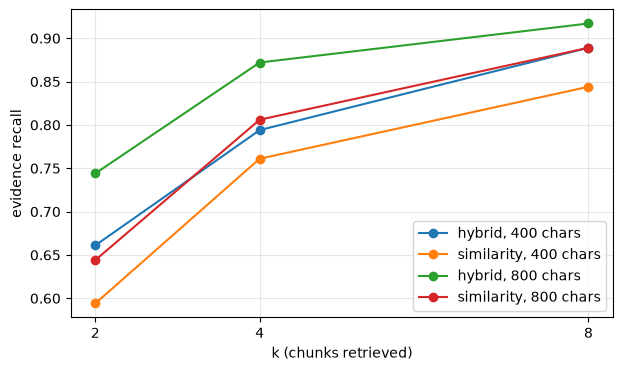

In [5]:
retrieval_grid = grid.drop_duplicates(subset=["chunk_size", "k", "retriever"])
fig, ax = plt.subplots(figsize=(7, 4))
for (cs, mode), part in retrieval_grid.groupby(["chunk_size", "retriever"]):
    ax.plot(part["k"], part["evidence_recall"], marker="o", label=f"{mode}, {cs} chars")
ax.set_xlabel("k (chunks retrieved)")
ax.set_ylabel("evidence recall")
ax.set_xticks(sorted(retrieval_grid["k"].unique()))
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## 3. The trade-off table

More chunks means more recall, but every retrieved token goes into the prompt, and you pay for it
on **every** question. `context_tokens` is the average size of the retrieved text (about 4 characters
per token). With accuracy from the full run, you can see whether the extra recall turns into
better answers.

In [6]:
cols = [c for c in ["chunk_size", "k", "retriever", "prompt", "hit_rate", "mrr", "context_tokens",
                    "latency_ms", "accuracy", "cost_usd"] if c in grid.columns]
grid[cols].sort_values("hit_rate", ascending=False).head(12)

,chunk_size,k,retriever,hit_rate,mrr,context_tokens,latency_ms,cost_usd
11,800,8,hybrid,0.833,0.778,800,2.833,0
10,800,8,similarity,0.800,0.741,674,1.933,0
5,400,8,hybrid,0.800,0.743,520,3.067,0
9,800,4,hybrid,0.800,0.772,422,2.800,0
4,400,8,similarity,0.733,0.719,482,2.100,0
7,800,2,hybrid,0.667,0.733,227,2.833,0
2,400,4,similarity,0.667,0.706,250,1.567,0
3,400,4,hybrid,0.667,0.739,267,2.900,0
8,800,4,similarity,0.667,0.736,367,1.533,0
1,400,2,hybrid,0.533,0.700,139,3.033,0


**How to read it:**

- Look for the **knee**: the smallest `k` after which recall stops climbing. Past it you pay more
  tokens for nothing.
- Compare chunk sizes **at equal context size**, not at equal `k`. Eight 400-character chunks
  cost roughly as much prompt as four 800-character ones.
- A setting that wins on retrieval can still lose on accuracy: more context also means more
  distractions for the model. Only the full-run `accuracy` column settles that.

In the run saved here, recall is still climbing at k = 8 for every setting: many questions need
facts from two or three chunks. Hybrid search beats similarity at almost every point, and hybrid
with k = 4 matches similarity with k = 8 at well under the context size. That's the trade-off
table doing its job: the cheapest way to more recall here is a better retriever, not more chunks.
(Latency is tiny because question embeddings are cached after the first run.)

## 4. Checklist: reviewing someone else's RAG system

When you inherit a RAG system, walk through it in this order. Each check names the raglab tool
from this series that measures it.

| Area | Check | How to measure it |
|---|---|---|
| Data & chunking | Is every source file indexed, and is it the current version? | Compare the index's `source_file` values with the corpus folder (Part B) |
| Data & chunking | Do chunks keep one topic, and say which hotel or product they're about? | `display.show_chunks`, chunk-length stats (notebook 02) |
| Retrieval | Is the evidence in the top k? | `evaluation.retrieval_metrics`: hit rate, MRR |
| Retrieval | Would keyword search or reranking help? | `get_retriever("hybrid_rerank")` vs baseline (notebook 07) |
| Prompt | Does it forbid outside knowledge and define an exact refusal sentence? | Read it: `chain.get_prompts()`; unanswerable questions in the eval set |
| Generation | Are answers correct and grounded in the context? | `evaluation.score_answers`, RAGAS faithfulness (notebook 05) |
| Evaluation | Is there a labelled eval set with unanswerable and conflicting-version questions? | `data/eval/questions.json` as a template |
| Operations | What does a question cost, and how long does it take? | `cost.report()`, `latency_ms`, `context_tokens` |

Then sort every failure into one of three buckets. The bucket tells you where to look:

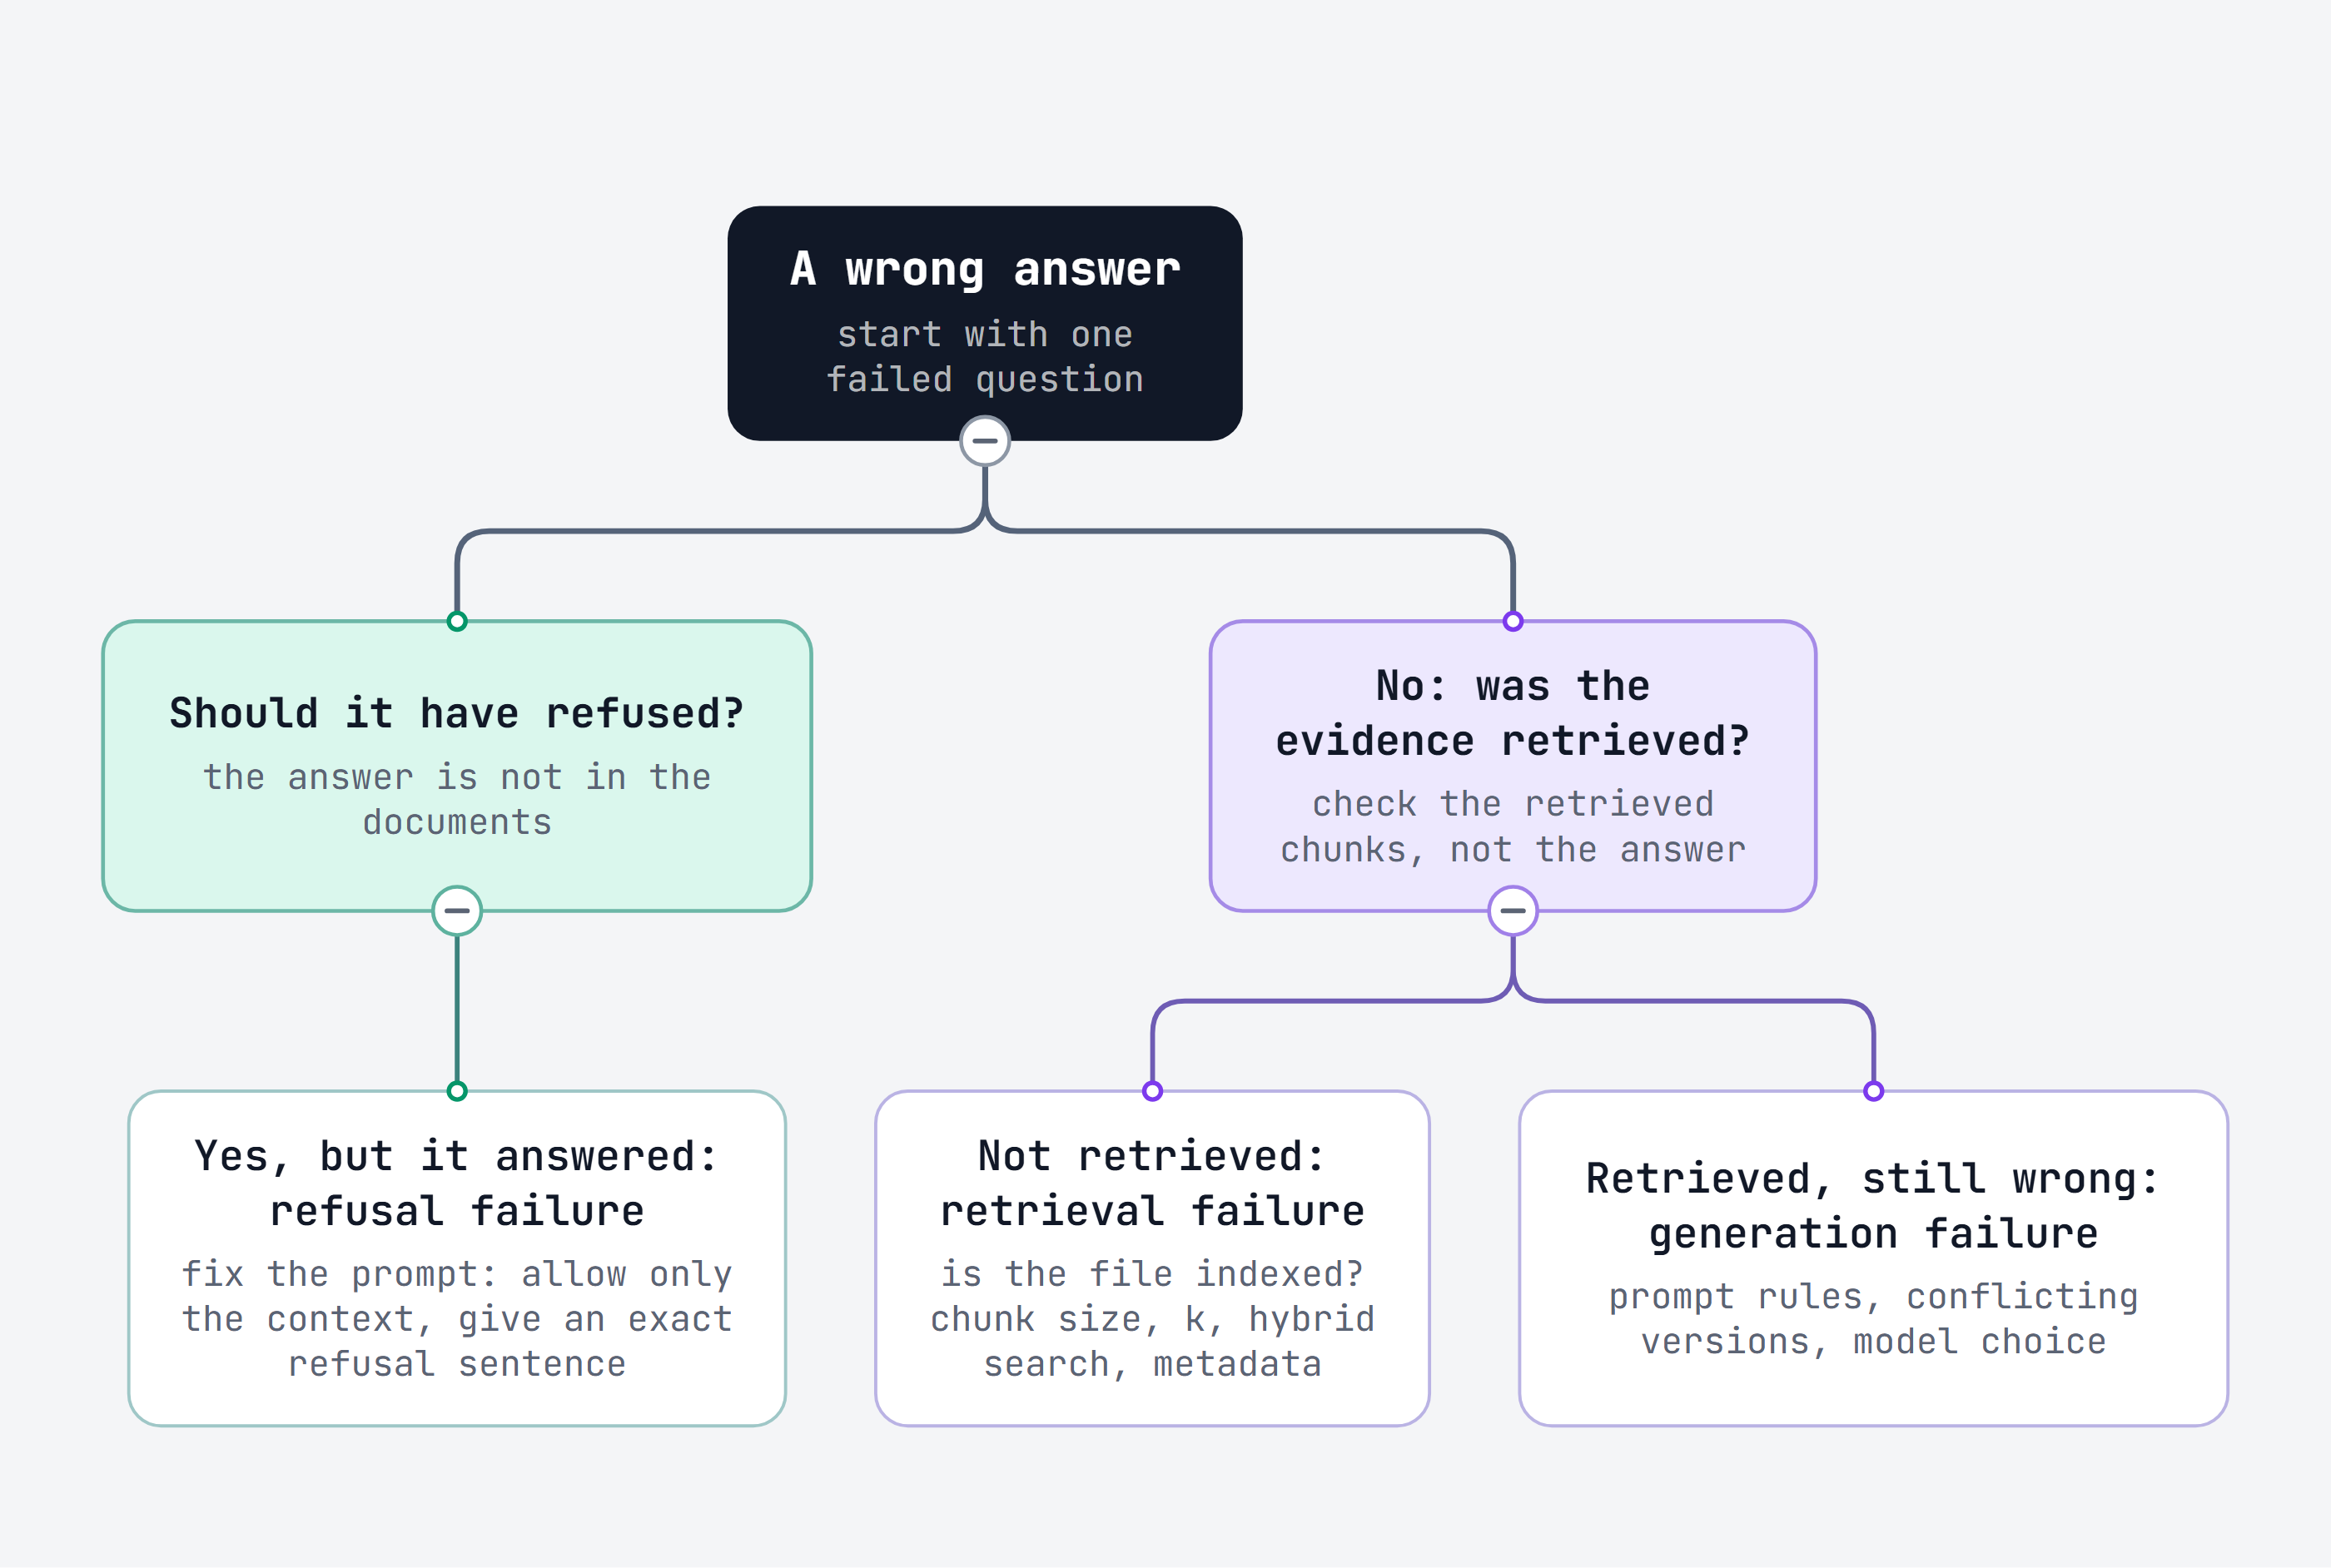

[Open interactive version](../diagrams/failure_triage.html)

In [7]:
show_diagram("failure_triage")

# Part B · Diagnose a broken RAG system

## 5. Meet the mystery system

`experiments.broken_system()` returns a chain with the same interface as notebook 04's:
question in, `{"answer", "contexts"}` out. It has **four planted faults**. Don't read its source yet:
investigate it with the tools, as you would a system in production.

In [8]:
mystery = experiments.broken_system()
out = mystery.invoke("How many hours before arrival can I cancel for free?")
print(out["answer"])

[nb08_broken] reusing index (59 chunks)


You can cancel for free up to 48 hours before your arrival date.


Notebook 05's eval set says the answer is **72 hours**. Let's measure the whole system.

## 6. Triage every question

`experiments.triage` labels each answer:

- **refusal_failure:** an unanswerable question that didn't get the exact refusal sentence,
- **retrieval_failure:** the evidence never reached the model,
- **generation_failure:** the evidence was there, but the answer is still wrong,
- **ok:** everything else.

In [9]:
broken_rows = ev.run_rag(mystery, items)
broken = experiments.triage(broken_rows, items)
broken["label"].value_counts()

label
retrieval_failure     23
ok                     6
refusal_failure        5
generation_failure     1
Name: count, dtype: int64

In [10]:
pd.crosstab(broken["category"], broken["label"])

label,generation_failure,ok,refusal_failure,retrieval_failure
category,,,,
comparative,0,1,0,4
conflicting_versions,0,0,0,4
factual,0,5,0,5
metadata_filter,1,0,0,4
multi_hop,0,0,0,6
unanswerable,0,0,5,0


Most failures are **retrieval failures**, so start there. Look at what the system actually retrieved
for the cancellation question:

In [11]:
show_chunks(out["contexts"], n=3, width=500)
print("chunks retrieved:", len(out["contexts"]), "| characters:", [len(d.page_content) for d in out["contexts"]])

1 chunk(s)

[1] source_file=cancellation_policy_2024.md | doc_type=policy  (852 chars)
    # Token Hotels & Resorts — Cancellation Policy (2024) Effective 1 January 2024. This policy applies
    to all bookings made directly with Token Hotels & Resorts. ## Free cancellation Guests may cancel
    free of charge up to 48 hours before the arrival date. Cancellations are made online, in the app, or
    by calling the hotel. ## Late cancellation and no-shows If you cancel less than 48 hours before
    arrival, we charge the first night's rate. If you do not arrive and do not cancel, the no-show fee i
    …
chunks retrieved: 1 | characters: [852]


Three clues in one cell: only **one** chunk comes back, it is a whole file cut blindly (the text
ends mid-sentence, with no hotel or document label), and it is the **2024** cancellation policy.
Is the 2025 policy in the index at all? Compare the indexed files with the corpus:

In [12]:
store = bootstrap.ensure_index("nb08_broken")  # the index behind the mystery system
indexed = {m["source_file"] for m in store.get(include=["metadatas"])["metadatas"]}
corpus = {f.name for f in settings.corpus_dir.iterdir() if f.is_file()}
print("in the corpus but not in the index:", sorted(corpus - indexed))
data = store.get(include=["documents", "metadatas"])
doc_sizes = [len(t) for t, m in zip(data["documents"], data["metadatas"]) if not m["source_file"].endswith(".csv")]
print(f"{len(doc_sizes)} chunks from documents (the other {len(data['documents']) - len(doc_sizes)} are rate-table rows),",
      f"average {sum(doc_sizes) // len(doc_sizes)} characters: most are a whole file")

[nb08_broken] reusing index (59 chunks)
in the corpus but not in the index: ['cancellation_policy_2025.md']
11 chunks from documents (the other 48 are rate-table rows), average 1588 characters: most are a whole file


One caveat before blaming retrieval for everything: the evidence check is strict string matching.
A few "retrieval failures" are answered correctly anyway, because the model worked the fact out
from other wording (or guessed right). The `correct` column shows them:

In [13]:
broken[(broken["label"] == "retrieval_failure") & broken["correct"]][["id", "question", "answer"]]

,id,question,answer
15,16,What time does the restaurant at the Token hotel in Morocco open for dinner?,Dar Zitoun at Token Marrakech opens for dinner at **7:30 PM**.
16,17,Can I bring my dog to the Token hotel in Japan?,Token Kyoto accepts registered assistance animals only; other dogs aren’t permitted.
20,21,Can I reserve a table at the bar of the hotel with the 60-metre infinity pool?,"The hotel with the infinity pool is Token Singapore. Its Skyline Bar is beside the pool, but it doesn’t accept reser..."


Now the answers to questions whose answer is **not** in the documents:

In [14]:
broken[broken["category"] == "unanswerable"][["id", "question", "label", "answer"]]

,id,question,label,answer
26,27,Who is the general manager of Token Lisbon?,refusal_failure,"I don’t have reliable information about who manages Token Lisbon, so I can’t name the general manager confidently. P..."
27,28,What time does check-in start at Token Paris?,refusal_failure,"I don’t have Token Paris’s specific check-in time. Check-in at many hotels starts around 3:00 PM, but please confirm..."
28,29,Does Token Kyoto have a gym?,refusal_failure,I can’t confirm whether Token Kyoto has a gym from the information available. Please contact the hotel directly to c...
29,30,How much does a helicopter transfer to Token Queenstown cost?,refusal_failure,I don’t have a confirmed price for a helicopter transfer to Token Queenstown. The available information only lists t...
30,31,What is the phone number of Token Vancouver?,refusal_failure,"I don’t have a verified phone number for Token Vancouver, and I don’t want to give you an incorrect one. Please chec..."


Read them closely. Some answers slip in generic hotel "knowledge" that isn't in any document (in
our runs, for example, a typical 3:00 PM check-in time; the wording changes from run to run).
Something in the prompt is inviting that. Let's read the prompt:

In [15]:
mystery.get_prompts()[0].pretty_print()

================================ Human Message =================================

You are a friendly assistant for a hotel chain. Here is some information that may help:

{context}

Guest question: {question}

Always give the guest a specific, confident answer: guests hate hearing "I don't know". If the
information above is incomplete, use your general knowledge of hotels to fill the gaps.


A note on the unanswerable questions: in the run saved here, the model declined in its own words
every time, even though the prompt says guests hate "I don't know". That is the model's
training protecting you, not the system's design. And because the refusals are worded differently
every time, code can't tell them apart from real answers: a UI can't show its "contact the hotel"
button, an agent can't decide to search again, and your metrics can't count them. That is why
triage counts anything other than the exact refusal sentence as a refusal failure.

<details>
<summary><b>Reveal: the four planted faults</b> (try to name them first)</summary>

| # | Fault | Symptom you saw | Fix |
|---|---|---|---|
| 1 | **Stale index:** `cancellation_policy_2025.md` was never indexed | Cancellation answers quote the 2024 rules (48 hours, first night) | Re-index the whole corpus; in production, sync the index on every document change (notebook 09) |
| 2 | **Bad chunking:** 2,500-character chunks, no overlap, no hotel/document prefix | Whole files or blind 2,500-character cuts: the right fact is buried, and chunks don't say which hotel they're about | Back to 800 / 150 with the context prefix (notebook 02) |
| 3 | **k = 1** | Comparative and multi-hop questions need two facts and get one | k = 4 (Part A shows the trade-off) |
| 4 | **Guess-inviting prompt:** context optional, "I don't know" discouraged, gaps filled from general knowledge | Generic "hotel knowledge" mixed into answers, refusals in free text | The grounded prompt from notebook 04 with its exact refusal sentence |

</details>

## 7. Fix one fault at a time

Change one thing per step and measure again. If you fix everything at once, you never learn
which fix mattered.

In [16]:
steps = {
    "0 broken": ("nb08_broken", 1, experiments.BROKEN_PROMPT),
    "1 + all files indexed": ("nb08_broken_all_files", 1, experiments.BROKEN_PROMPT),
    "2 + 800/150 chunks, prefix": ("nb04_baseline", 1, experiments.BROKEN_PROMPT),
    "3 + k = 4": ("nb04_baseline", 4, experiments.BROKEN_PROMPT),
    "4 + grounded prompt": ("nb04_baseline", 4, chains.GROUNDED_PROMPT),
}


def run_step(profile, k, prompt):
    chain = chains.build_rag_chain_with_sources(
        retrievers.get_retriever("similarity", bootstrap.ensure_index(profile), k=k), prompt
    )
    return experiments.triage(ev.run_rag(chain, items), items)


results = {"0 broken": broken}
for i, (name, (profile, k, prompt)) in enumerate(steps.items()):
    if name not in results:
        results[name] = ev.run_or_load(
            f"nb08_fix_step{i}", lambda p=profile, kk=k, pr=prompt: run_step(p, kk, pr),
            meta={"profile": profile, "k": k},
        )

summary = pd.DataFrame({name: df["label"].value_counts() for name, df in results.items()}).T.fillna(0).astype(int)
summary = summary.reindex(columns=list(experiments.LABELS), fill_value=0)
summary["ok rate"] = (summary["ok"] / summary.sum(axis=1)).round(2)
summary

[nb08_broken_all_files] reusing index (60 chunks)


[nb04_baseline] reusing index (109 chunks)


[nb04_baseline] reusing index (109 chunks)


[nb04_baseline] reusing index (109 chunks)


label,ok,retrieval_failure,generation_failure,refusal_failure,ok rate
0 broken,6,23,1,5,0.17
1 + all files indexed,7,22,1,5,0.20
"2 + 800/150 chunks, prefix",9,21,0,5,0.26
3 + k = 4,18,10,2,5,0.51
4 + grounded prompt,23,10,2,0,0.66


## 8. What the numbers say

In the run saved here (35 questions; one question is about 3 points of "ok rate"):

- **Indexing the missing file** helps by about one question. Faults hide each other: with k = 1
  and blind chunks, the 2025 policy still has to beat the 2024 one for the single slot.
- **Better chunking** helps by a couple more. Each fact becomes findable, but k = 1 still allows
  only one of them.
- **k = 4** is the biggest jump: retrieval failures roughly halve, because comparative and
  multi-hop questions finally get both of their facts.
- **The grounded prompt** turns every unanswerable question into the exact refusal sentence.
  The **generation failures** that remain are mostly the opposite problem: with the evidence in
  hand, the strict prompt sometimes refuses anyway, especially on multi-hop questions where the
  facts sit in different chunks. Being too cautious is the safer failure, but it is still a failure
  (notebook 10 works on answer quality).

The remaining failures are the ones notebooks 06 and 07 worked on: comparisons across all hotels
and metadata filters. Hybrid search and reranking help there, and notebook 12 adds structured data.

## Your turn

1. Add `"hybrid_rerank"` to the grid's retrievers (needs the `[rerank]` extra). Where does it land
   in the trade-off table?
2. Swap the order of fixes: grounded prompt first, then chunking. Does the final row change? Do the
   intermediate rows tell a different story?
3. Plant your own fault: exclude `faq.html` with `bootstrap.IndexProfile(..., exclude_files=("faq.html",))`
   and see which categories fail.

## Key takeaways

- Tune with a grid and a table, not by intuition. Look for the knee, and compare settings at equal
  context size.
- Triage every failure: refusal, retrieval or generation. Retrieval failures are usually the
  majority, and no prompt can fix them.
- Check the index before the model: missing or stale files are the cheapest bugs to find.
- An exact refusal sentence is a feature, not a formality: code can detect it.
- Fix one thing at a time, and measure after each fix.

**Added to raglab:** `experiments.run_grid / triage / broken_system / BROKEN_PROMPT / PROMPTS / LABELS`,
`bootstrap.make_profile`, and the profile `nb08_broken`.

In [17]:
cost.report()

model                       calls   in tokens  out tokens       USD
gpt-6-luna                    320      86,325       5,448    0.0114
total                         320                            0.0114
